<a href="https://colab.research.google.com/github/omcepedav87-ux/App1/blob/main/Notebook_Modelo_Publicacion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Mi primera aplicación de datos en Colab

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/USUARIO/REPO/blob/main/NOTEBOOK.ipynb)

*(Cambia `USUARIO`, `REPO` y `NOTEBOOK` en este botón por tus datos de GitHub. Así cualquier persona abre tu notebook en Colab con un clic.)*

**Cómo usarlo:** en cada recuadro con campos (nombres, números, casillas) cambia los valores de la derecha y pulsa el botón de ejecutar (▶) de esa celda. El código queda oculto y no se puede dañar al escribir en los campos.

**Para ver el código** de una celda de formulario: menú ⋮ de la celda → *Mostrar código* (Show code).

## Parte 1. Tres valores y un gráfico

La aplicación recibe tres nombres con sus valores y los muestra como barras, líneas o torta.

Total: 3300   Promedio: 1100.0   Mayor: Enero


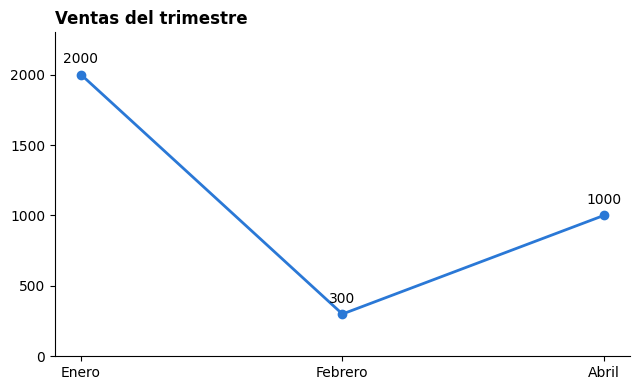

In [3]:
#@title Tres valores en un gráfico { display-mode: "form" }
#@markdown Escribe un nombre y un valor para cada dato, elige el tipo de gráfico y pulsa ejecutar.
titulo = "Ventas del trimestre" #@param {type:"string"}
nombre_1 = "Enero" #@param {type:"string"}
valor_1 = 2000 #@param {type:"number"}
nombre_2 = "Febrero" #@param {type:"string"}
valor_2 = 300 #@param {type:"number"}
nombre_3 = "Abril" #@param {type:"string"}
valor_3 = 1000 #@param {type:"number"}
tipo_grafico = "líneas" #@param ["barras", "líneas", "torta"]

import matplotlib.pyplot as plt

nombres = [nombre_1, nombre_2, nombre_3]
valores = [valor_1, valor_2, valor_3]
AZUL = "#2a78d6"
COLORES = ["#2a78d6", "#eb6834", "#1baf7a"]

if tipo_grafico == "torta" and (min(valores) < 0 or sum(valores) == 0):
    print("La torta necesita valores positivos. Cambia los valores o el tipo de gráfico.")
else:
    print(f"Total: {sum(valores):g}   Promedio: {sum(valores) / 3:.1f}   Mayor: {nombres[valores.index(max(valores))]}")
    fig, ax = plt.subplots(figsize=(6.5, 4))
    if tipo_grafico == "barras":
        barras = ax.bar(nombres, valores, color=AZUL, width=0.55)
        ax.bar_label(barras, fmt="%g", padding=3)
    elif tipo_grafico == "líneas":
        ax.plot(nombres, valores, color=AZUL, marker="o", linewidth=2)
        for n, v in zip(nombres, valores):
            ax.annotate(f"{v:g}", (n, v), textcoords="offset points", xytext=(0, 8), ha="center")
    else:
        ax.pie(valores, labels=nombres, colors=COLORES, autopct="%1.0f%%",
               startangle=90, counterclock=False,
               wedgeprops={"edgecolor": "white", "linewidth": 2})
    ax.set_title(titulo, loc="left", fontweight="bold")
    if tipo_grafico != "torta":
        ax.spines[["top", "right"]].set_visible(False)
        ax.set_ylim(min(0, min(valores) * 1.1), max(valores) * 1.15 if max(valores) > 0 else 1)
    plt.tight_layout()
    plt.show()

## Parte 2. Un Excel y un minidashboard

Con la casilla marcada usa datos de ejemplo. Si la desmarcas, aparece un botón para cargar tu propio Excel.

**Formato del Excel:** una fila de títulos y tres columnas: el nombre de cada categoría, el valor real y la meta. Por ejemplo, `sede`, `ventas`, `meta`.

Saving ejemplo.xlsx to ejemplo.xlsx


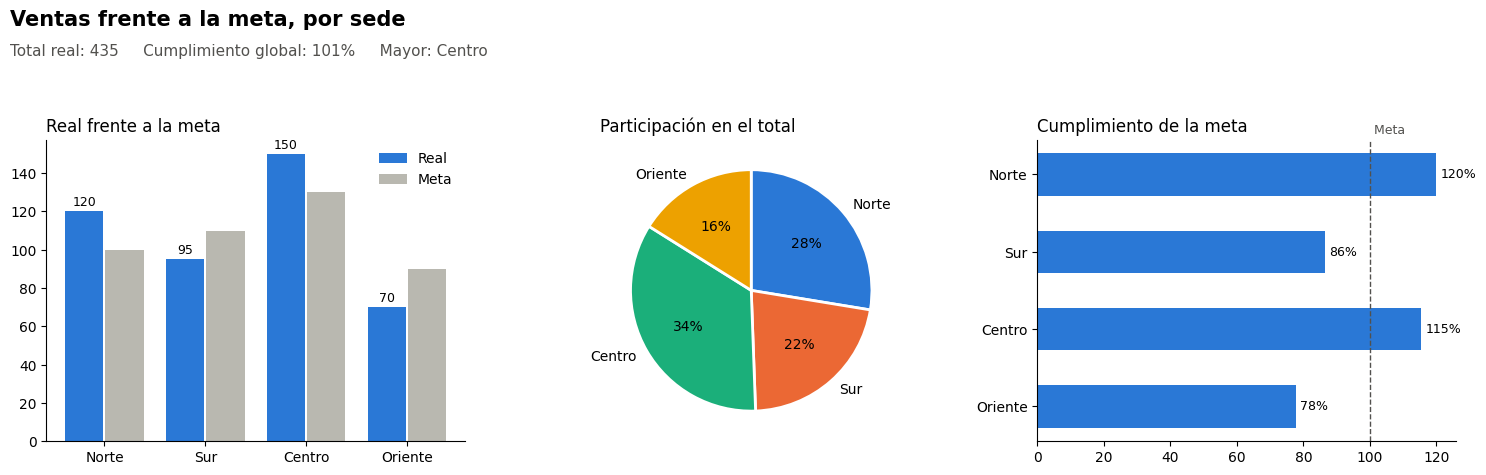

In [5]:
#@title Minidashboard desde un Excel { display-mode: "form" }
#@markdown Marca la casilla para usar los datos de ejemplo. Si la desmarcas, se abre un botón para cargar tu Excel (.xlsx).
usar_ejemplo = False #@param {type:"boolean"}
titulo_dashboard = "Ventas frente a la meta, por sede" #@param {type:"string"}

import io
import pandas as pd
import matplotlib.pyplot as plt

AZUL, GRIS, NARANJA = "#2a78d6", "#b9b8b0", "#eb6834"
COLORES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]


def cargar_datos(usar_ejemplo):
    """Devuelve un DataFrame: ejemplo o el Excel que cargue la persona."""
    if usar_ejemplo:
        return pd.DataFrame({"sede": ["Norte", "Sur", "Centro", "Oriente"],
                             "ventas": [120, 95, 150, 70],
                             "meta": [100, 110, 130, 90]})
    from google.colab import files
    subido = files.upload()
    if not subido:
        raise ValueError("No cargaste ningún archivo.")
    nombre, contenido = next(iter(subido.items()))
    return pd.read_excel(io.BytesIO(contenido))


def validar(df):
    """Deja tres columnas (categoria, real, meta) o explica qué está mal."""
    if df.shape[1] < 3:
        raise ValueError("El Excel debe tener 3 columnas: nombre, valor real y meta.")
    df = df.iloc[:, :3].dropna().copy()
    df.columns = ["categoria", "real", "meta"]
    if df.empty:
        raise ValueError("El Excel no tiene filas con datos completos.")
    try:
        df["real"] = pd.to_numeric(df["real"])
        df["meta"] = pd.to_numeric(df["meta"])
    except ValueError:
        raise ValueError("La segunda y la tercera columna deben contener solo números.")
    if (df["real"] < 0).any() or (df["meta"] < 0).any():
        raise ValueError("Los valores no pueden ser negativos.")
    if df["real"].sum() == 0:
        raise ValueError("La suma de los valores reales es cero; no hay nada que graficar.")
    return df


try:
    datos = validar(cargar_datos(usar_ejemplo))
except Exception as error:
    print("No se pudo crear el dashboard:", error)
else:
    total = datos["real"].sum()
    cumplimiento_total = total / datos["meta"].sum() * 100 if datos["meta"].sum() else float("nan")
    mejor = datos.loc[datos["real"].idxmax(), "categoria"]
    cumplimiento = (datos["real"] / datos["meta"].where(datos["meta"] != 0) * 100)

    fig, axs = plt.subplots(1, 3, figsize=(15, 4.8))
    fig.suptitle(titulo_dashboard, x=0.01, ha="left", fontsize=15, fontweight="bold")
    fig.text(0.01, 0.885, f"Total real: {total:,.0f}     Cumplimiento global: {cumplimiento_total:.0f}%     Mayor: {mejor}",
             fontsize=11, color="#52514e")

    # 1) real frente a meta
    x = range(len(datos))
    barras = axs[0].bar([i - 0.2 for i in x], datos["real"], width=0.38, color=AZUL, label="Real")
    axs[0].bar([i + 0.2 for i in x], datos["meta"], width=0.38, color=GRIS, label="Meta")
    axs[0].bar_label(barras, fmt="%g", padding=2, fontsize=9)
    axs[0].set_xticks(list(x))
    axs[0].set_xticklabels(datos["categoria"])
    axs[0].set_title("Real frente a la meta", loc="left")
    axs[0].legend(frameon=False)
    axs[0].spines[["top", "right"]].set_visible(False)

    # 2) participación en el total
    axs[1].pie(datos["real"], labels=datos["categoria"], colors=COLORES[:len(datos)],
               autopct="%1.0f%%", startangle=90, counterclock=False,
               wedgeprops={"edgecolor": "white", "linewidth": 2})
    axs[1].set_title("Participación en el total", loc="left")

    # 3) cumplimiento de la meta
    barras = axs[2].barh(datos["categoria"], cumplimiento, color=AZUL, height=0.55)
    axs[2].axvline(100, color="#52514e", linestyle="--", linewidth=1)
    axs[2].text(100, 1.01, " Meta", transform=axs[2].get_xaxis_transform(), color="#52514e", fontsize=9, va="bottom")
    axs[2].bar_label(barras, fmt="%.0f%%", padding=3, fontsize=9)
    axs[2].invert_yaxis()
    axs[2].set_title("Cumplimiento de la meta", loc="left")
    axs[2].spines[["top", "right"]].set_visible(False)

    plt.tight_layout(rect=[0, 0, 1, 0.86])
    plt.show()

## Parte 3. Una aplicación que interactúa: sumar dos números

La persona escribe dos números en los campos y la aplicación muestra la suma. Para usarla no hace falta tocar el código.

In [7]:
#@title Suma de dos números { display-mode: "form" }
#@markdown Escribe los dos números y pulsa ejecutar.
primer_numero = 40 #@param {type:"number"}
segundo_numero = 30 #@param {type:"number"}

suma = primer_numero + segundo_numero
print(f"{primer_numero:g} + {segundo_numero:g} = {suma:g}")

40 + 30 = 70


## Tu turno

1. **Cambia la aplicación de la Parte 3** para que además tenga una lista desplegable con la operación (`suma`, `resta`, `multiplicación`, `división`). Se agrega con una línea como `operacion = "suma" #@param ["suma", "resta", "multiplicación", "división"]`. Cuida la división entre cero.
2. **Cambia los datos** de la Parte 1 o de la Parte 2 por los de tu proyecto.
3. **Publícalo:** ejecuta todo desde cero, guarda con *Archivo → Guardar una copia en GitHub* y agrega el botón de Colab al README de tu repositorio.

*Recuerda: el repositorio es público. No subas claves ni datos privados.*